# Transport Balance

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path
import plotly.express as px
import numpy as np

pd.options.mode.chained_assignment = None

In [8]:
# Load transport workflow outputs (portable, repository-relative)
repo_root = Path.cwd().parent if Path.cwd().name == "plots" else Path.cwd()
OUTPUT_DIR = repo_root / "transport" / "output_data"
csv_candidates = sorted(OUTPUT_DIR.glob("transport_*.csv"))

if not csv_candidates:
    raise FileNotFoundError(f"No transport output files found in {OUTPUT_DIR}")

dfs = []
for csv_file in csv_candidates:
    df_tmp = pd.read_csv(csv_file, dtype={"country": str, "scenario": str}, keep_default_na=False, na_values=[""])
    dfs.append(df_tmp)

df_raw = pd.concat(dfs, ignore_index=True)
df_raw.columns = [str(c).strip() for c in df_raw.columns]
df_raw["country"] = df_raw["country"].astype(str).str.strip()
df_raw["scenario"] = df_raw["scenario"].astype(str).str.strip()

# Parse scenario into year + scenario_name
scenario_year_name = df_raw["scenario"].str.extract(r"^(?P<year>\d{4})_(?P<name>.+)$")
scenario_name_year = df_raw["scenario"].str.extract(r"^(?P<name>.+)_(?P<year>\d{4})$")

year_from_pattern = pd.to_numeric(scenario_year_name["year"], errors="coerce")
year_from_pattern = year_from_pattern.fillna(pd.to_numeric(scenario_name_year["year"], errors="coerce"))
year_from_pattern = year_from_pattern.fillna(pd.to_numeric(df_raw["scenario"], errors="coerce"))
df_raw["year"] = year_from_pattern.fillna(0).astype(int)

scenario_name = scenario_year_name["name"].fillna(scenario_name_year["name"])
scenario_name = scenario_name.fillna(df_raw["scenario"])
scenario_name = scenario_name.replace({"all": "Historic", "ALL": "Historic"})
scenario_name = np.where(df_raw["scenario"].str.fullmatch(r"\d{4}"), "Historic", scenario_name)
df_raw["scenario_name"] = pd.Series(scenario_name, index=df_raw.index).astype(str)

def col_or_zero(col_name):
    if col_name in df_raw.columns:
        return pd.to_numeric(df_raw[col_name], errors="coerce").fillna(0)
    return pd.Series(0.0, index=df_raw.index)

# Carrier decomposition from workflow outputs
road_electricity = col_or_zero("road electricity")
road_hydrogen = col_or_zero("total road fcev")
road_biomass = col_or_zero("road biomass")
road_liq_hydrocarbons = col_or_zero("road oil") - road_biomass
road_liq_hydrocarbons = road_liq_hydrocarbons.clip(lower=0)

dom_aviation_biomass = col_or_zero("total aviation biomass")
dom_aviation_liq_hydrocarbons = col_or_zero("total domestic aviation") - dom_aviation_biomass
dom_aviation_liq_hydrocarbons = dom_aviation_liq_hydrocarbons.clip(lower=0)

dom_maritime_hydrogen = col_or_zero("total navigation hydrogen")
dom_maritime_biomass = col_or_zero("total navigation biomass")
dom_maritime_ammonia = col_or_zero("total navigation ammonia")
dom_maritime_liq_hydrocarbons = col_or_zero("total navigation oil")

rail_electricity = col_or_zero("electricity rail")
rail_hydrogen = col_or_zero("total rail hydrogen")
rail_liq_hydrocarbons = col_or_zero("total rail") - rail_hydrogen - rail_electricity
rail_liq_hydrocarbons = rail_liq_hydrocarbons.clip(lower=0)

int_aviation_liq_hydrocarbons = col_or_zero("total international aviation")
int_maritime_liq_hydrocarbons = col_or_zero("total international navigation")

base_cols = df_raw[["country", "scenario_name", "year"]].copy()
base_cols["scenario_year"] = base_cols["scenario_name"] + "_" + base_cols["year"].astype(str)

components = {
    ("road", "electricity"): road_electricity,
    ("road", "hydrogen"): road_hydrogen,
    ("road", "biomass"): road_biomass,
    ("road", "liq. hydrocarbons"): road_liq_hydrocarbons,
    ("aviation", "biomass"): dom_aviation_biomass,
    ("aviation", "liq. hydrocarbons"): dom_aviation_liq_hydrocarbons,
    ("int. aviation", "liq. hydrocarbons"): int_aviation_liq_hydrocarbons,
    ("maritime", "hydrogen"): dom_maritime_hydrogen,
    ("maritime", "biomass"): dom_maritime_biomass,
    ("maritime", "ammonia"): dom_maritime_ammonia,
    ("maritime", "liq. hydrocarbons"): dom_maritime_liq_hydrocarbons,
    ("int. maritime", "liq. hydrocarbons"): int_maritime_liq_hydrocarbons,
    ("rail", "electricity"): rail_electricity,
    ("rail", "hydrogen"): rail_hydrogen,
    ("rail", "liq. hydrocarbons"): rail_liq_hydrocarbons,
}

long_parts = []
for (mode, carrier), values in components.items():
    tmp = base_cols.copy()
    tmp["mode"] = mode
    tmp["carrier"] = carrier
    tmp["value"] = values
    long_parts.append(tmp)

long_df = pd.concat(long_parts, ignore_index=True)

mode_grouped_order = ["road", "rail", "aviation (all)", "maritime (all)"]
long_df_grouped = long_df.copy()
long_df_grouped["mode_grouped"] = long_df_grouped["mode"]
long_df_grouped.loc[long_df_grouped["mode"].str.contains("aviation"), "mode_grouped"] = "aviation (all)"
long_df_grouped.loc[long_df_grouped["mode"].str.contains("maritime"), "mode_grouped"] = "maritime (all)"
long_df_grouped["mode_grouped"] = pd.Categorical(
    long_df_grouped["mode_grouped"], categories=mode_grouped_order, ordered=True
)

# Sum duplicates created by domestic + international grouped categories
long_df_grouped_sum = (
    long_df_grouped
    .groupby(["country", "scenario_name", "year", "scenario_year", "mode_grouped", "carrier"], as_index=False)["value"]
    .sum()
)

print(f"Loaded {len(dfs)} file(s) from {OUTPUT_DIR}")
print("Files      :", [p.name for p in csv_candidates])
print(f"Rows       : {len(long_df_grouped_sum):,}")
print(f"Countries  : {sorted(long_df_grouped_sum['country'].unique())}")
print(f"Scenarios  : {sorted(long_df_grouped_sum['scenario_name'].unique())}")
print(f"Years      : {sorted(long_df_grouped_sum['year'].unique())}")
print(f"Carriers   : {sorted(long_df_grouped_sum['carrier'].unique())}")

Loaded 16 file(s) from c:\Users\eduque\Documents\models\sectoral-energy-demands\transport\output_data
Files      : ['transport_all_2020.csv', 'transport_BAU_2030.csv', 'transport_BAU_2035.csv', 'transport_BAU_2040.csv', 'transport_BAU_2045.csv', 'transport_BAU_2050.csv', 'transport_Optimistic_2030.csv', 'transport_Optimistic_2035.csv', 'transport_Optimistic_2040.csv', 'transport_Optimistic_2045.csv', 'transport_Optimistic_2050.csv', 'transport_Progressive_2030.csv', 'transport_Progressive_2035.csv', 'transport_Progressive_2040.csv', 'transport_Progressive_2045.csv', 'transport_Progressive_2050.csv']
Rows       : 30,720
Countries  : ['Egypt', 'Morocco', 'Namibia', 'South Africa']
Scenarios  : ['BAU', 'Historic', 'Optimistic', 'Progressive']
Years      : [np.int64(2020), np.int64(2030), np.int64(2035), np.int64(2040), np.int64(2045), np.int64(2050)]
Carriers   : ['ammonia', 'biomass', 'electricity', 'hydrogen', 'liq. hydrocarbons']


C:\Users\eduque\AppData\Local\Temp\ipykernel_7948\382638441.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  long_df_grouped


In [3]:
transport_colors = {
    "liq. hydrocarbons": "#1c3f52",
    "electricity": "#f58220",
    "hydrogen": "#179c7d",
    "biomass": "#b2d235",
    "ammonia": "#fce356",
}
country_dic = {
    "MA": "Morocco", "EG": "Egypt", "ZA": "South Africa", "NA": "Namibia",
    "Morocco": "Morocco", "Egypt": "Egypt", "South Africa": "South Africa", "Namibia": "Namibia",
}

def plot_per_country(df, facet_gap=0.08, ytick_size=12, fig_width=1200, fig_height=420, bargap=0.15):
    figs = {}
    mode_order = ["road", "rail", "aviation (all)", "maritime (all)"]
    carrier_order = ["electricity", "hydrogen", "liq. hydrocarbons", "biomass", "ammonia"]
    scenario_base = ["Historic", "BAU", "Progressive", "Optimistic"]
    scenario_year_order = [
        f"{sc}_{yr}"
        for sc in scenario_base
        for yr in sorted(df["year"].unique())
        if f"{sc}_{yr}" in set(df["scenario_year"])
]

    for cty, d in df.groupby("country"):
        full_name = country_dic.get(cty, cty)
        fig = px.bar(
            d,
            x="scenario_year",
            y="value",
            color="carrier",
            facet_col="mode_grouped",
            facet_col_spacing=facet_gap,
            category_orders={
                "mode_grouped": mode_order,
                "carrier": carrier_order,
                "scenario_year": scenario_year_order,
            },
            color_discrete_map=transport_colors,
            barmode="stack",
            labels={
                "value": "Final end use energy demand (TWh)",
                "carrier": "Carrier",
                "scenario_year": "Scenario_Year",
            },
            title=f"Final energy by mode, scenario & year -- {full_name}",
        )
        fig.update_yaxes(
            matches=None,
            showticklabels=True,
            ticks="outside",
            automargin=True,
            tickfont=dict(size=ytick_size),
        )
        fig.update_layout(
            bargap=bargap,
            width=fig_width,
            height=fig_height,
            margin=dict(l=90, r=20, t=60, b=40),
            legend_title_text="Carrier",
        )
        fig.for_each_annotation(lambda a: a.update(text=a.text.split("=", 1)[-1]))
        figs[cty] = fig

    return figs

figs = plot_per_country(long_df_grouped_sum)
for cty in sorted(figs):
    figs[cty].show()

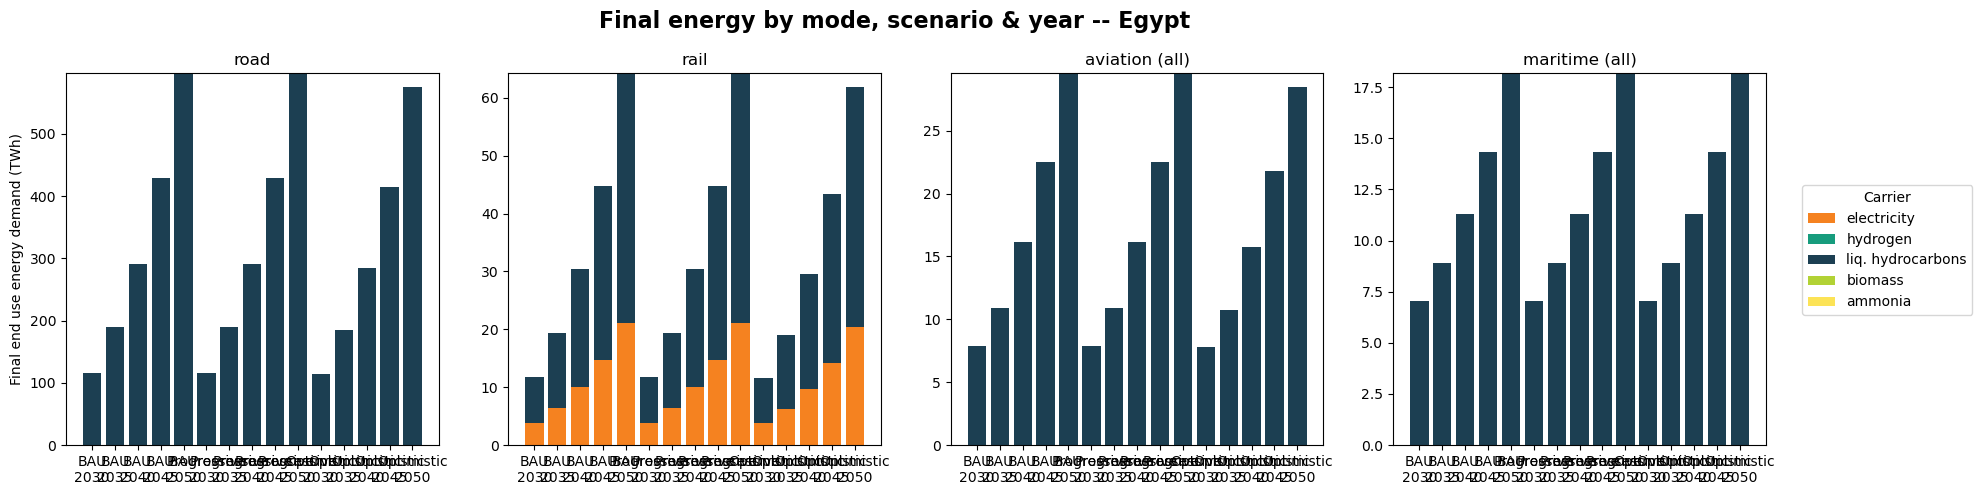

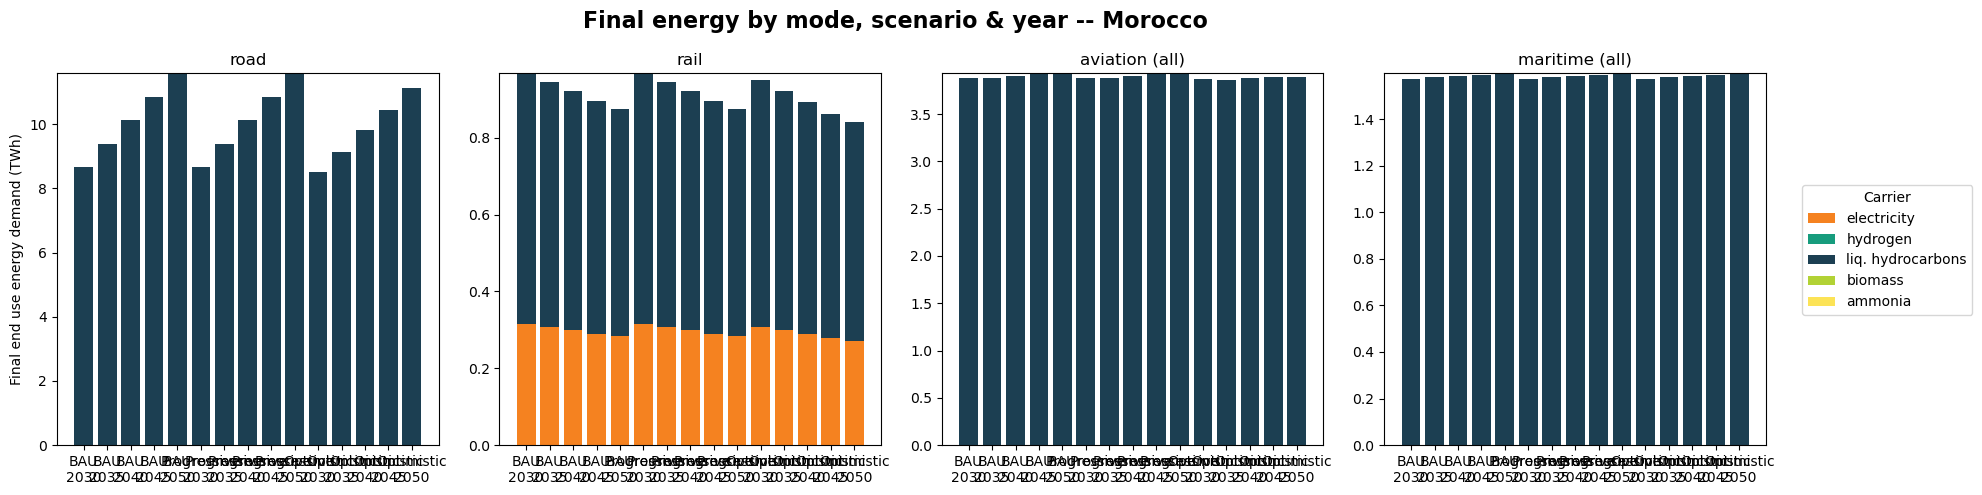

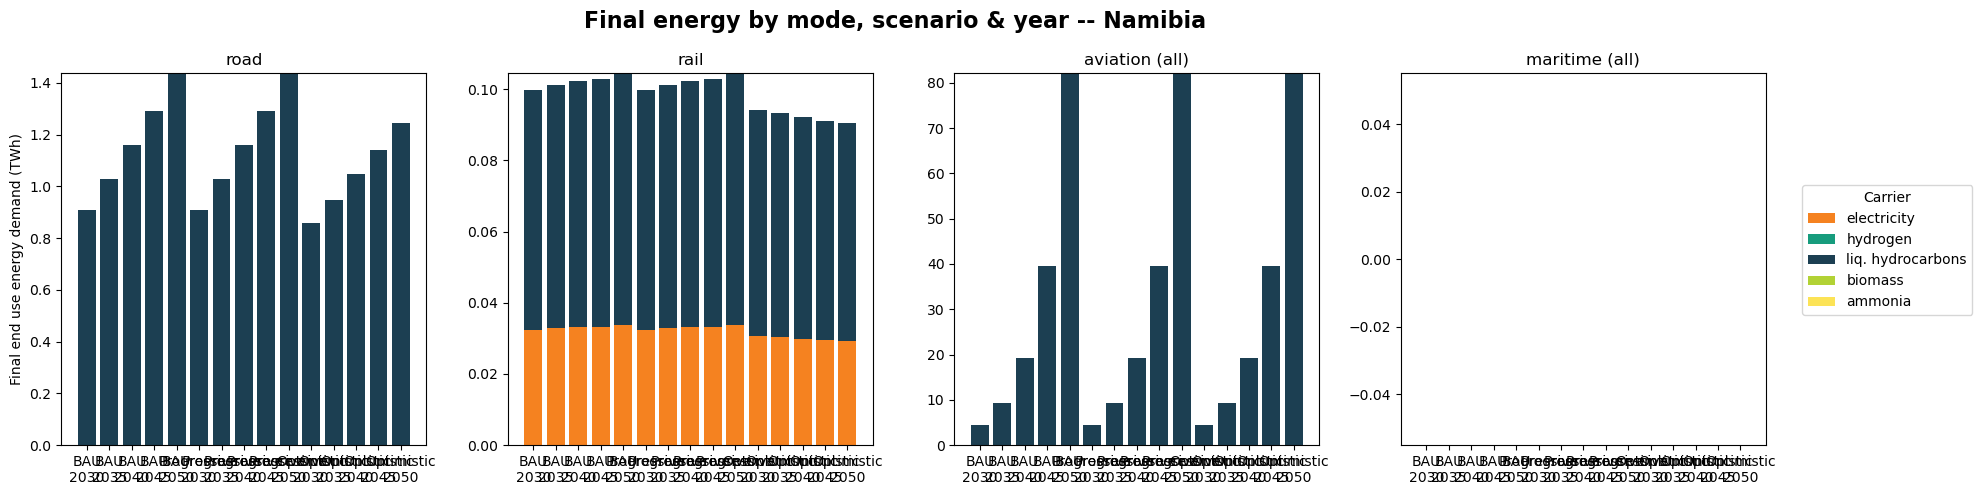

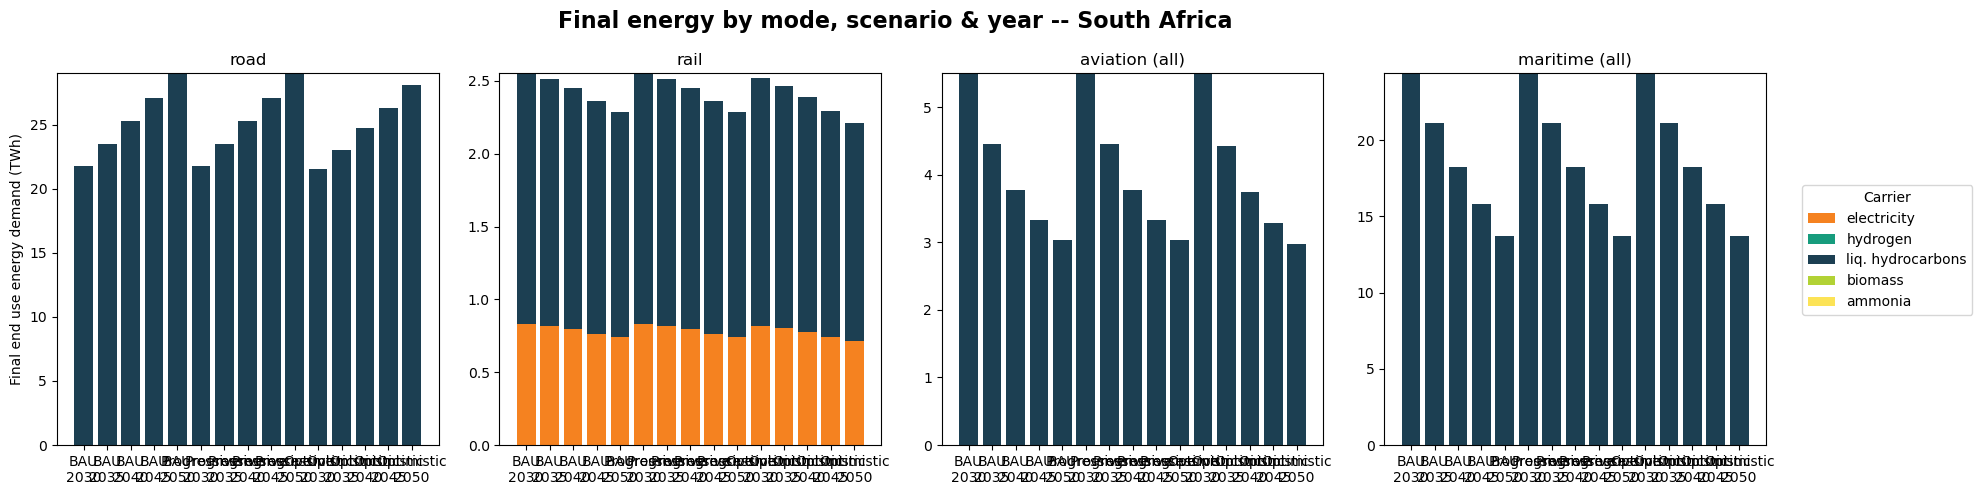

In [4]:
mode_order = ["road", "rail", "aviation (all)", "maritime (all)"]
carrier_order = ["electricity", "hydrogen", "liq. hydrocarbons", "biomass", "ammonia"]
country_dic = {
    "MA": "Morocco", "EG": "Egypt", "ZA": "South Africa", "NA": "Namibia",
    "Morocco": "Morocco", "Egypt": "Egypt", "South Africa": "South Africa", "Namibia": "Namibia",
}

scenario_base = ["Historic", "BAU", "Progressive", "Optimistic"]
scenario_year_order = [
    f"{sc}_{yr}"
    for sc in scenario_base
    for yr in sorted(long_df_grouped_sum["year"].unique())
    if f"{sc}_{yr}" in set(long_df_grouped_sum["scenario_year"])
]

for cty, d in long_df_grouped_sum.groupby("country"):
    full_name = country_dic.get(cty, cty)
    fig, axs = plt.subplots(1, len(mode_order), figsize=(18, 5), sharey=False)
    for i, mode in enumerate(mode_order):
        ax = axs[i]
        d_mode = d[d["mode_grouped"] == mode].copy()
        d_mode["scenario_year"] = pd.Categorical(
            d_mode["scenario_year"], categories=scenario_year_order, ordered=True
        )
        pivot = d_mode.pivot_table(
            index="scenario_year", columns="carrier", values="value", aggfunc="sum", observed=False
        ).fillna(0)
        for carrier in carrier_order:
            if carrier not in pivot.columns:
                pivot[carrier] = 0
        pivot = pivot[carrier_order]
        pivot.index = [lbl.replace("_", "\n") for lbl in pivot.index]

        bottom = np.zeros(len(pivot.index))
        for carrier in carrier_order:
            values = pivot[carrier].values
            ax.bar(
                pivot.index,
                values,
                bottom=bottom,
                color=transport_colors.get(carrier, "#cccccc"),
                label=carrier,
            )
            bottom += values

        ax.set_title(mode)
        ax.set_xlabel("")
        if i == 0:
            ax.set_ylabel("Final end use energy demand (TWh)")
        ax.tick_params(axis="x", rotation=0)

    fig.suptitle(f"Final energy by mode, scenario & year -- {full_name}", fontsize=16, weight="bold")
    fig.legend(carrier_order, title="Carrier", loc="center left", bbox_to_anchor=(1.0, 0.5))
    plt.tight_layout()
    plt.show()

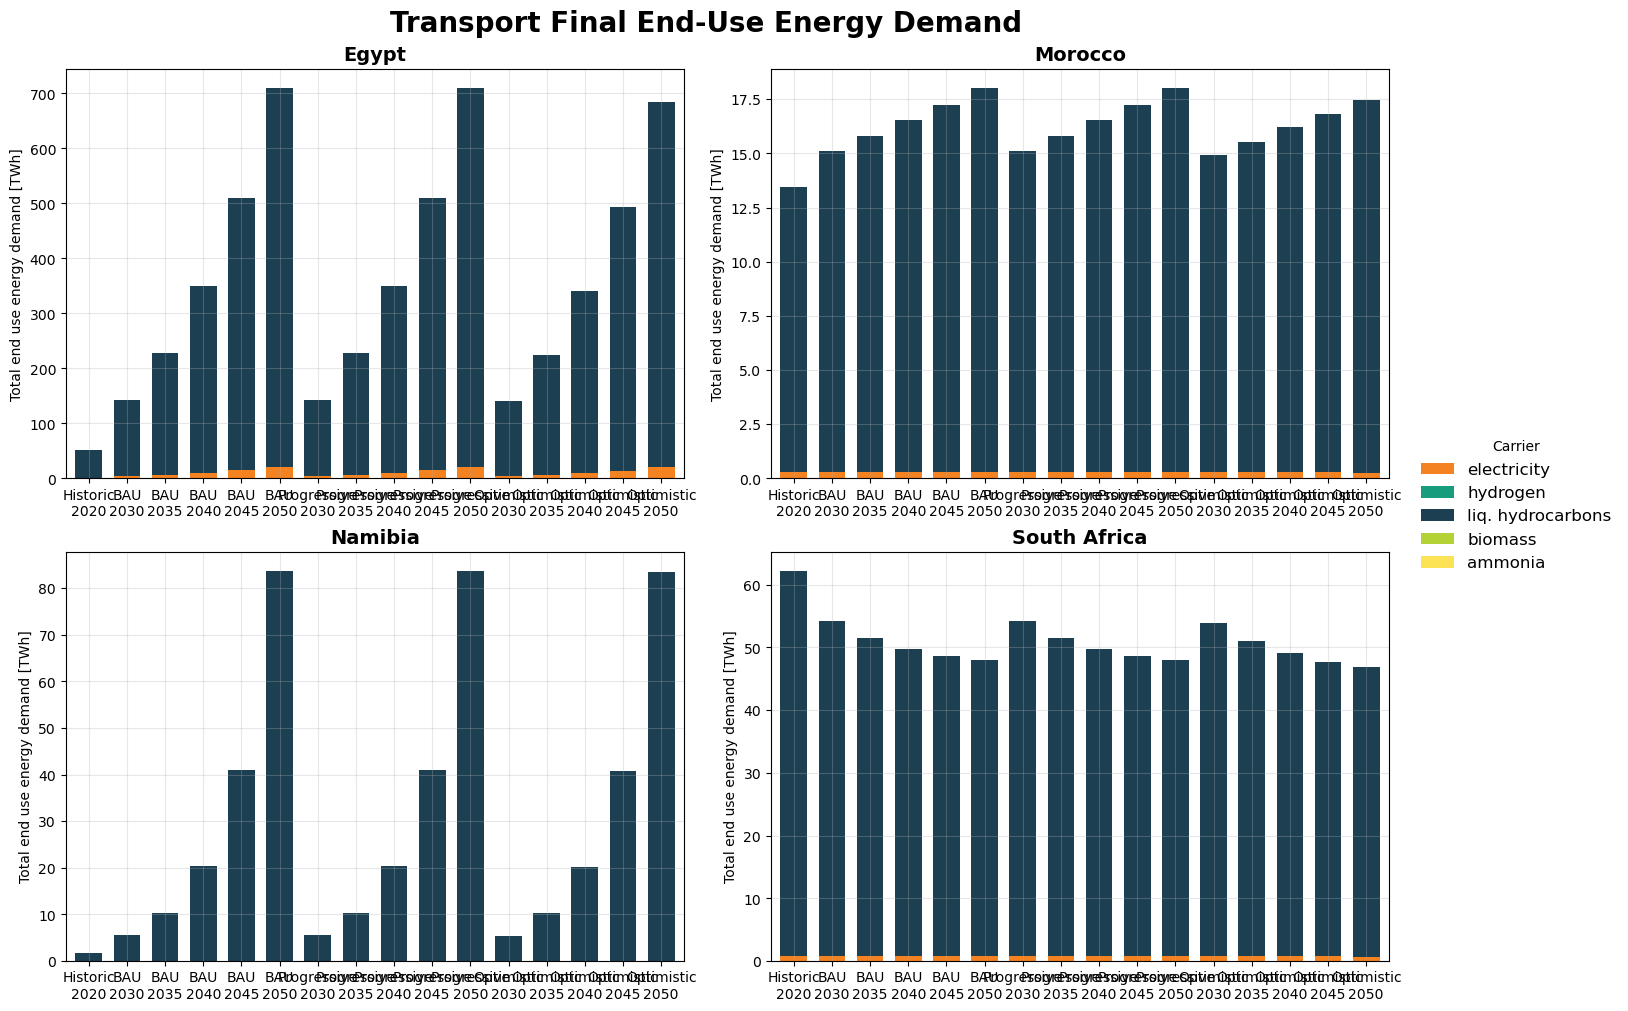

In [9]:
# Aggregate all grouped modes for each country/scenario_year/carrier
df_agg_transport = (
    long_df_grouped_sum
    .groupby(["country", "scenario_year", "carrier"], as_index=False)["value"]
    .sum()
)

carrier_order = ["electricity", "hydrogen", "liq. hydrocarbons", "biomass", "ammonia"]
scenario_base = ["Historic", "BAU", "Progressive", "Optimistic"]
scenario_year_order = [
    f"{sc}_{yr}"
    for sc in scenario_base
    for yr in sorted(long_df_grouped_sum["year"].unique())
    if f"{sc}_{yr}" in set(long_df_grouped_sum["scenario_year"])
]

country_dic = {
    "MA": "Morocco", "EG": "Egypt", "ZA": "South Africa", "NA": "Namibia",
    "Morocco": "Morocco", "Egypt": "Egypt", "South Africa": "South Africa", "Namibia": "Namibia",
}

def plot_transport_bar_agg(df_agg, country_code, ax):
    df_country = df_agg[df_agg["country"] == country_code].copy()
    df_country = df_country[df_country["scenario_year"].notna()]
    if df_country.empty:
        ax.set_visible(False)
        return

    df_country["scenario_year"] = pd.Categorical(
        df_country["scenario_year"], categories=scenario_year_order, ordered=True
    )
    df_pivot = (
        df_country.pivot(index="scenario_year", columns="carrier", values="value")
        .fillna(0)
        .reindex(columns=carrier_order, fill_value=0)
    )
    if df_pivot.empty:
        ax.set_visible(False)
        return

    df_pivot.index = [str(lbl).replace("_", "\n") for lbl in df_pivot.index]
    colors = [transport_colors.get(c, "#cccccc") for c in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, width=0.7, legend=False, stacked=True)
    ax.set_title(country_dic.get(country_code, country_code), fontsize=14, weight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Total end use energy demand [TWh]")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=0)

countries = [c for c in sorted(df_agg_transport["country"].dropna().astype(str).unique()) if c]
ncols = min(2, len(countries))
nrows = int(np.ceil(len(countries) / ncols))

fig, axs = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5 * nrows), constrained_layout=True)
axs_flat = np.array(axs).flatten()

for idx, cty in enumerate(countries):
    plot_transport_bar_agg(df_agg_transport, cty, axs_flat[idx])

for ax in axs_flat[len(countries):]:
    ax.set_visible(False)

fig.suptitle("Transport Final End-Use Energy Demand", fontsize=20, weight="bold")
handles, labels = axs_flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels, title="Carrier", loc="center left",
    bbox_to_anchor=(1.0, 0.5), fontsize="large", frameon=False,
 )
plt.show()

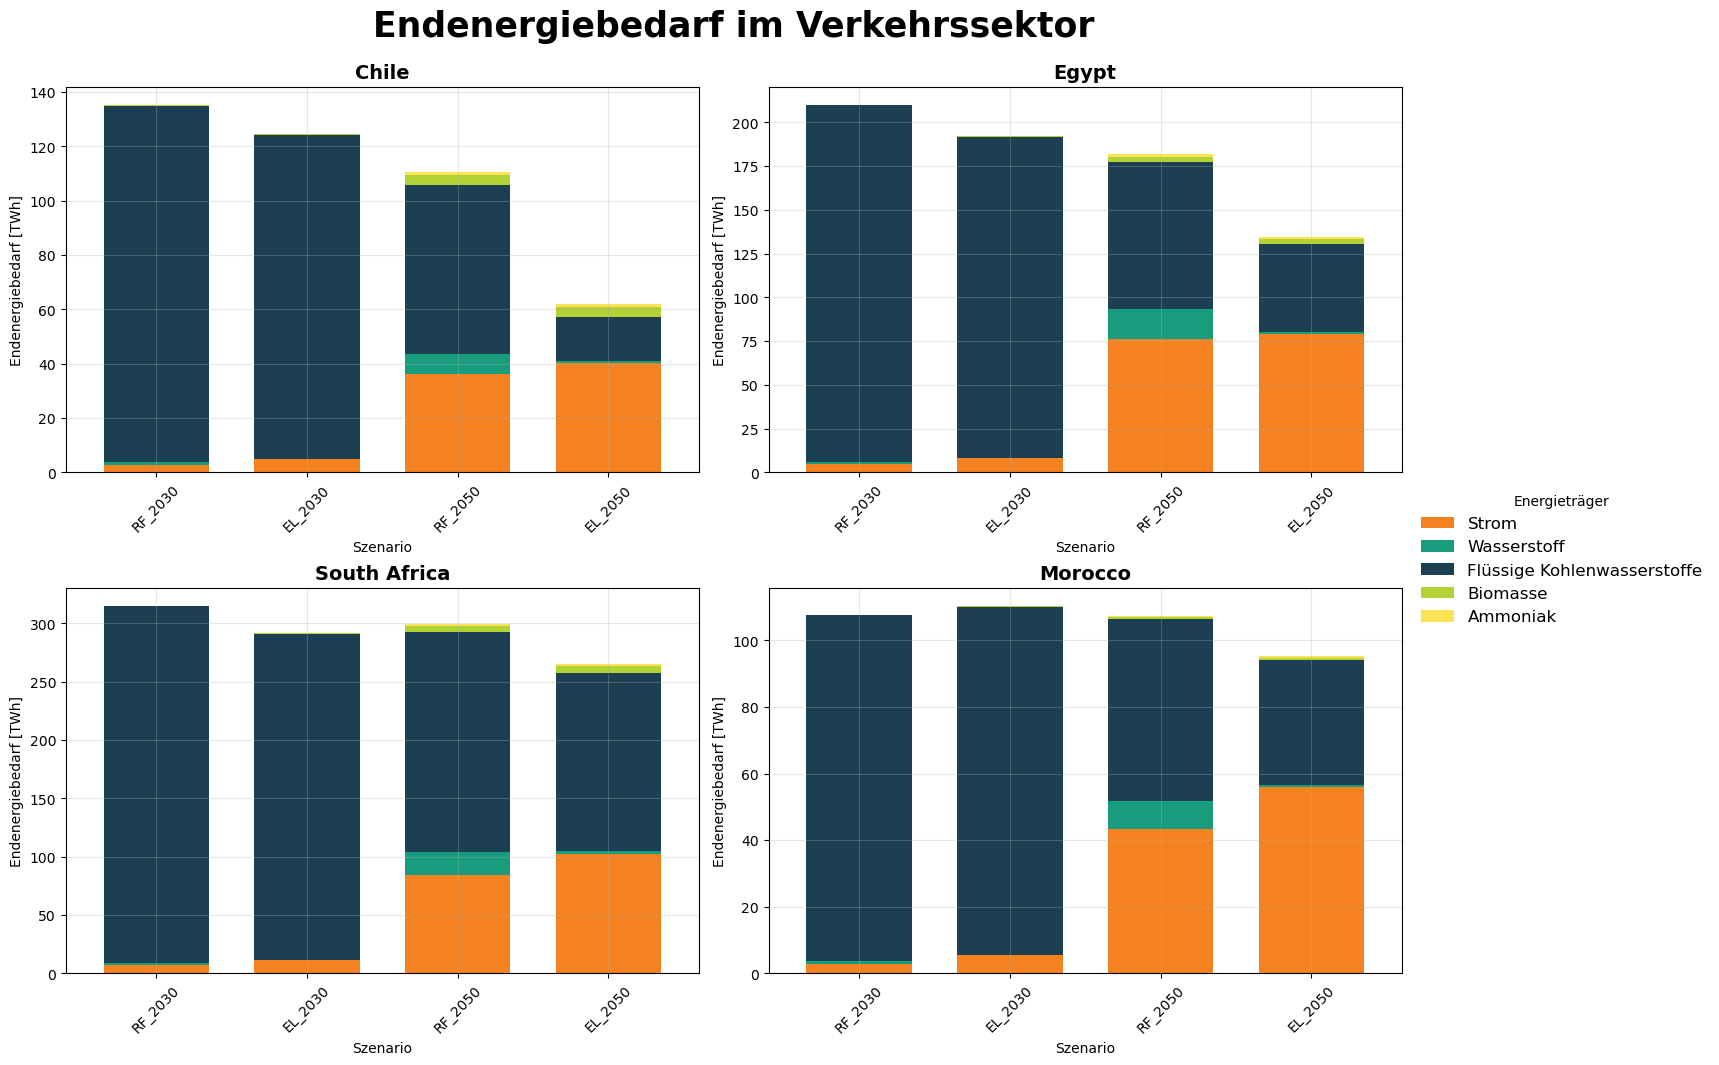

In [ ]:
# German mapping for carriers
carrier_legend_de = {
    'electricity': 'Strom',
    'hydrogen': 'Wasserstoff',
    'liq. hydrocarbons': 'Flüssige Kohlenwasserstoffe',
    'biomass': 'Biomasse',
    'ammonia': 'Ammoniak'
}

# Define color mapping for carriers
transport_colors = {
    'liq. hydrocarbons': '#1c3f52',
    'electricity': '#f58220',
    'hydrogen': '#179c7d',
    'biomass': '#b2d235',
    'ammonia': '#fce356',
}
carrier_order = ['electricity', 'hydrogen', 'liq. hydrocarbons', 'biomass', 'ammonia']
scenario_order = ['RF_2030', 'EL_2030', 'RF_2050', 'EL_2050']
country_dic = {"CL": "Chile", "EG": "Egypt", "MA": "Morocco", "ZA": "South Africa"}

y_axis_label_de = 'Endenergiebedarf [TWh]'

# Aggregate all modes for each country, scenario, and carrier
df_agg = (
    long_df_grouped
    .groupby(["country", "scenario", "carrier"], as_index=False)["value"]
    .sum()
)

def plot_transport_bar_agg(df_agg, country_code, ax):
    df_country = df_agg[df_agg['country'] == country_code].copy()
    df_country['scenario'] = pd.Categorical(df_country['scenario'], categories=scenario_order, ordered=True)
    df_pivot = df_country.pivot(index='scenario', columns='carrier', values='value')
    df_pivot = df_pivot[carrier_order]  # Ensure column order
    colors = [transport_colors[c] for c in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, width=0.7, legend=False, stacked=True)
    ax.set_title(country_dic.get(country_code, country_code), fontsize=14, weight='bold')
    ax.set_xlabel('Szenario')  # German for Scenario
    ax.set_ylabel(y_axis_label_de)
    ax.grid(alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

fig, axs = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

plot_transport_bar_agg(df_agg, 'CL', axs[0, 0])
plot_transport_bar_agg(df_agg, 'EG', axs[0, 1])
plot_transport_bar_agg(df_agg, 'ZA', axs[1, 0])
plot_transport_bar_agg(df_agg, 'MA', axs[1, 1])

fig.suptitle('Endenergiebedarf im Verkehrssektor', fontsize=25, weight='bold', y=1.05, x=0.52)

handles, labels = axs[0,0].get_legend_handles_labels()
labels_de = [carrier_legend_de.get(label, label) for label in labels]
fig.legend(handles, labels_de, title='Energieträger', loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='large', frameon=False)
fig.savefig("Transport_demand_bar_plot.png", dpi=300, bbox_inches='tight')
plt.show()